In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Oefening 1.1: Lees met pd.read_parquet het bestand ../data/uber_dataset_2025-01.parquet in. Deze bevat een (willekeurig gekozen) tiende van alle uber ritten in New York in Januari 2025. Bekijk het resulterende dataframe. Begrijp je de betekenis van alle kolommen?

In [3]:
uber_df = pd.read_parquet("../../data/uber_dataset_2025-01.parquet") # Adjust path to file location

In [4]:
uber_df

,ride_id,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,pickup_zone_id,dropoff_zone_id,trip_miles,trip_seconds,base_passenger_fare,tolls,sales_tax,tips,driver_pay
0,2707637,2025-01-05 11:33:26,2025-01-05 11:33:39,2025-01-05 11:34:58,2025-01-05 11:54:18,163,144,3.45,1160,27.20,0.00,2.56,0.00,15.96
1,10151529,2025-01-16 22:52:08,2025-01-16 22:55:45,2025-01-16 22:55:59,2025-01-16 23:33:40,155,265,19.01,2261,53.35,0.00,4.72,4.00,50.22
2,12331759,2025-01-19 23:09:59,2025-01-19 23:27:05,2025-01-19 23:28:09,2025-01-19 23:41:19,106,14,5.95,790,18.74,0.00,1.66,4.18,16.92
3,1935159,2025-01-04 08:06:33,2025-01-04 08:10:19,2025-01-04 08:12:19,2025-01-04 08:42:28,167,151,5.98,1809,12.80,0.00,1.14,0.00,22.01
4,13446232,2025-01-21 19:52:49,2025-01-21 19:55:41,2025-01-21 19:57:43,2025-01-21 20:28:10,14,71,9.71,1827,35.22,0.00,3.11,0.00,36.22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1536690,18855548,2025-01-29 20:41:17,2025-01-29 20:45:18,2025-01-29 20:46:50,2025-01-29 21:29:04,241,265,24.96,2534,58.36,18.91,0.00,0.00,85.85
1536691,5422319,2025-01-09 19:33:32,2025-01-09 19:35:16,2025-01-09 19:35:17,2025-01-09 19:39:33,167,60,0.65,256,8.91,0.00,0.79,0.00,4.61
1536692,19717083,2025-01-31 06:49:39,2025-01-31 06:52:41,2025-01-31 06:53:20,2025-01-31 06:58:35,233,170,0.89,315,33.00,0.00,2.92,0.00,15.88
1536693,20291747,2025-01-31 21:43:46,2025-01-31 21:47:09,2025-01-31 21:47:22,2025-01-31 21:58:46,37,36,1.81,684,11.81,0.00,1.11,0.00,9.11


Oefening 1.2: Neem met onderstaande code een sample (steekproef) van 100 taxiritten. Wat zijn het gemiddelde en de mediaan van het aantal afgelegde mijlen? Waarom is de een hoger dan de ander? Draai dezelfde code nog een keer. Waarom geven we een seed als argument mee?

In [5]:
seed = 42
df_sample = uber_df.sample(100, random_state = seed)                       
print(f"mean = {df_sample['trip_miles'].mean()}")
print(f"median = {df_sample['trip_miles'].median()}")

mean = 5.904399999999999
median = 2.8049999999999997


Oefening 1.3: Doe 100 verschillende (onhankelijke) steekproeven met weer 100 taxiritten elk, en herhaal bovenstaande. Je hebt nu 100 verschillende inschattingen van het gemiddelde en de mediaan. Plot deze om de spreiding hierin te zien. Interpreteer het resultaat. Waarom gebruiken we nu een random number generator (rng)?

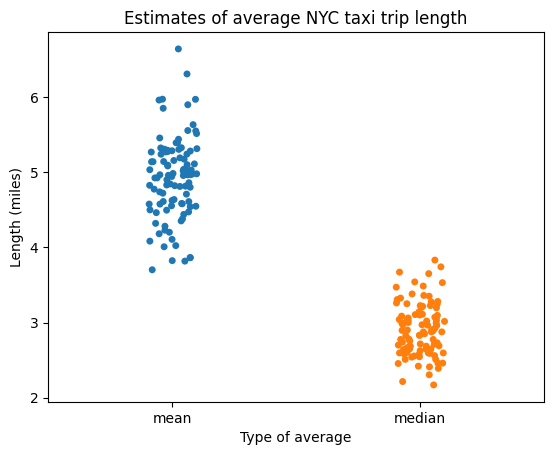

In [6]:
mean_results = []
median_results = []
n_samples = 100


rng = np.random.default_rng(seed=42)

for _ in range(n_samples):
    df_sample = uber_df.sample(100, random_state = rng)                     
    mean_results += [df_sample['trip_miles'].mean()]
    median_results += [df_sample['trip_miles'].median()]

fig, ax = plt.subplots()

sns.stripplot(data=[mean_results, median_results], jitter=0.1, size=5, ax=ax)

ax.set_xticks([0, 1])
ax.set_xticklabels(['mean', 'median'])
ax.set_ylabel('Length (miles)')
ax.set_xlabel('Type of average')
ax.set_title('Estimates of average NYC taxi trip length')

plt.show()

Oefening 1.4: Introduceer nu zelf outliers door te doen alsof voor een op de 300 ritjes de afstand per ongeluk in voet is ingevuld i.p.v. in mijl. Maak dezelfde plot als in de vorige opgave. Wat valt je op? Door welke eigenschappen van het gemiddelde / de mediaan komt dit? Wanneer zou je in de praktijk het gemiddelde willen gebruiken en wanneer de mediaan?

In [7]:
# One in 300 rides has trip_miles reported in feet accidently
outlier_df = uber_df.assign(trip_miles = lambda df: df['trip_miles'].mask(
          df['ride_id'] % 300 == 0, 
          df['trip_miles'] * 5280)
      )

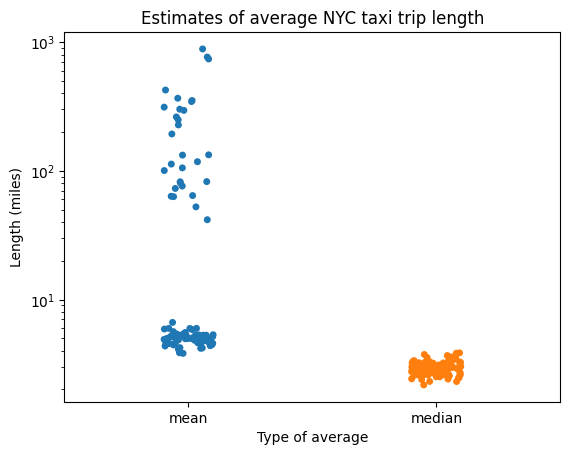

In [8]:
mean_results = []
median_results = []
n_samples = 100

rng = np.random.default_rng(seed = 42)
for _ in range(n_samples):
    df_sample = outlier_df.sample(100, random_state = rng)
    mean_results += [df_sample['trip_miles'].mean()]
    median_results += [df_sample['trip_miles'].median()]

# Seaborn interprets the list of lists as two separate categories
fig, ax = plt.subplots()

sns.stripplot(data=[mean_results, median_results], jitter=0.1, size=5, ax=ax)

ax.set_yscale('log')
ax.set_xticks([0, 1])
ax.set_xticklabels(['mean', 'median'])
ax.set_ylabel('Length (miles)')
ax.set_xlabel('Type of average')
ax.set_title('Estimates of average NYC taxi trip length')

plt.show()

Oefening 1.5: Neem een steekproef van 10 000 taxiritten. In welke 5 pickup_zones wordt het vaakst een fooi gegeven? Maak je als uber chauffeur in deze pickup zones dus een grote kans om een fooi te krijgen?

In [9]:
rng = np.random.default_rng(seed = 42)

(
uber_df
    .sample(10000, random_state = rng)
    .assign(was_tipped = lambda df: (df['tips'] > 0))
    .groupby(['pickup_zone_id'], as_index = False)
    .agg(fraction_tipped = ('was_tipped', 'mean'))
    .sort_values(by = "fraction_tipped", ascending=False)
    .head(5)
     )

,pickup_zone_id,fraction_tipped
9,12,1.0
42,46,1.0
182,194,1.0
50,54,0.5
109,120,0.5


Oefening 1.6: Bereken nu voor deze vijf districten op de hele uber_df (dus, zonder eerst een steekproef te nemen) hoe vaak er fooi gegeven wordt. Hoe kan dit?

In [10]:
(
    uber_df
    .assign(was_tipped = lambda df: (df['tips'] > 0))
    .groupby(['pickup_zone_id'], as_index = False)
    .agg(fraction_tipped = ('was_tipped', 'mean'))
    .loc[pd.col('pickup_zone_id').isin([46, 12, 194, 54, 120])]
    )

,pickup_zone_id,fraction_tipped
10,12,0.322034
44,46,0.216000
52,54,0.269095
114,120,0.138158
188,194,0.178082


Oefening 2.1: Voor welk deel van alle uberritten is er een fooi gegeven?

In [11]:
real_fraction_tipped = uber_df.assign(was_tipped = lambda df: (df['tips'] > 0)).agg(fraction_tipped = ('was_tipped', 'mean')).iloc[0, 0]
real_fraction_tipped

np.float64(0.1793667578797354)

Oefening 2.2: Neem nu een steekproef van 100 ritten. Voor welk deel van de ritten in deze steekproef is er een fooi gegeven? Gebruik onderstaande functie om op basis van deze steekproef een Confidence Interval te berekenen voor het deel van de ritten waarvoor een fooi wordt gegeven. 

Bevat deze de bij de vorige oefening berekende waarde? Hoe verandert de grootte van het interval als je meer ritten in de steekproef mee neemt?

In [12]:
rng = np.random.default_rng(seed = 42)
sample_df = uber_df.sample(100, random_state = rng)

In [13]:
sample_df_fraction_tipped = sample_df.assign(was_tipped = lambda df: (df['tips'] > 0)).agg(fraction_tipped = ('was_tipped', 'mean')).iloc[0,0]
sample_df_fraction_tipped

np.float64(0.18)

In [14]:
from statsmodels.stats.proportion import proportion_confint

def get_ci_for_fraction_of_rides_tipped(fraction_tipped: float, N: int, alpha = 0.05) -> Tuple[float, float]:
    """Use the Clopper-Pearson method to calculate a (1-alpha)% confidence interval for the fraction of rides where the driver received a tip.

    input:

    fraction_tipped: The fraction of rides in the sample where the driver received a tip.
    N: The number of rides in the sample

    returns:
    [CI lower limit, CI upper limit]
    """
    return proportion_confint(count=int(N*fraction_tipped), nobs=N, method='beta', alpha = alpha) 

In [15]:
(
    sample_df
    .assign(was_tipped = lambda df: (df['tips'] > 0))
    .agg(fraction_tipped = ('was_tipped', 'mean'))
    .T
    .assign(fraction_tipped_ci = lambda df: df['fraction_tipped']
            .apply(lambda x: get_ci_for_fraction_of_rides_tipped(x, 100)))
)

,fraction_tipped,fraction_tipped_ci
was_tipped,0.18,"(0.11031122915326057, 0.2694770859668119)"


Bonus: Oefening 2.3: Als je bovenstaande herhaald voor 1000 onafhankelijke steekproeven (van 100 ritten elk), hoe vaak bevat de CI dan de echte (bij 1.1 berekende) waarde?

In [16]:
rng = np.random.default_rng(seed = 42)

sample_size = 100
repetitions = 1000
print(f"{real_fraction_tipped=}")

real_value_in_ci = []
for it in range(repetitions):
    if it%100 == 0:
        print(f"Processed {it} repetitions.")

    df_sample = uber_df.sample(sample_size, random_state = rng).assign(was_tipped = lambda df: (df['tips'] > 0))
    ci = df_sample.agg(fraction_tipped = ('was_tipped', 'mean')).T.assign(fraction_tipped_ci = lambda df: df['fraction_tipped'].apply(lambda x: get_ci_for_fraction_of_rides_tipped(x, sample_size)))['fraction_tipped_ci'].item()
    real_value_in_ci += [(ci[0] <= real_fraction_tipped <= ci[1])]

print(sum(real_value_in_ci) / len(real_value_in_ci))

real_fraction_tipped=np.float64(0.1793667578797354)
Processed 0 repetitions.
Processed 100 repetitions.
Processed 200 repetitions.
Processed 300 repetitions.
Processed 400 repetitions.
Processed 500 repetitions.
Processed 600 repetitions.
Processed 700 repetitions.
Processed 800 repetitions.
Processed 900 repetitions.
0.962


Bonus: Oefening 2.4 (Sample size estimation I): Wat zou de gemiddelde breedte van een 95%-CI voor een steekproef van 30 ritten zijn als het echte deel van de ritten waar een fooi zou worden gegeven 0.15 zou zijn? In welke context zou deze vraag relevant zijn?

In [17]:
sample_size = 30
real_fraction_tipped = 0.15

rng = np.random.default_rng(42)
ci_widths = []
for _ in range(100): # The higher the more accurate

    number_tipped = rng.binomial(sample_size, real_fraction_tipped) # Randomly simulate whether the ride was tipped or not
    ci = proportion_confint(count=number_tipped, nobs=sample_size, method='beta', alpha = 0.05) 
    width_ci = ci[1] - ci[0]
    ci_widths.append(width_ci)


print(f"average ci width: {sum(ci_widths)/len(ci_widths)}")

average ci width: 0.2705187206118235


Bonus: Oefening 2.5 (Sample size estimation II): Hoe groot moet de steekproefgrootte zijn om een gemiddelde CI-breedte van 0.2 te krijgen als het echte deel van de ritten waar een fooi wordt gegeven 0.15 is? En als dat 0.3 zou zijn? Hoe zou je deze berekening in de praktijk gebruiken?

In [18]:
real_fraction_tipped = 0.15

rng = np.random.default_rng(42)

for sample_size in range(30, 100, 5):
    ci_widths = []
    for _ in range(100): # The higher the more accurate
            
        number_tipped = rng.binomial(sample_size, real_fraction_tipped) # Randomly simulate whether the ride was tipped or not

        ci = proportion_confint(count=number_tipped, nobs=sample_size, method='beta', alpha = 0.05) 
        width_ci = ci[1] - ci[0]
        ci_widths.append(width_ci)

    print(f"sample size = {sample_size}, average ci width: {sum(ci_widths)/len(ci_widths)}")


sample size = 30, average ci width: 0.2705187206118235
sample size = 35, average ci width: 0.2532685021543304
sample size = 40, average ci width: 0.23260679186383712
sample size = 45, average ci width: 0.22581884202434735
sample size = 50, average ci width: 0.2094195902294655
sample size = 55, average ci width: 0.20047526892632989
sample size = 60, average ci width: 0.19495550638605338
sample size = 65, average ci width: 0.1785897539979354
sample size = 70, average ci width: 0.17792187892501032
sample size = 75, average ci width: 0.17160544426798627
sample size = 80, average ci width: 0.16738069424891425
sample size = 85, average ci width: 0.1605533515169365
sample size = 90, average ci width: 0.15423771974577852
sample size = 95, average ci width: 0.15158410171103143


Bonus: Oefening 2.6: Draai onderstaande code om een Bayesiaanse credible interval te bereken met als prior verdeling Beta(alpha = 0.5, beta = 0.5). Vervang deze prior door je eigen prior verdeling (dwz. welke verdeling van kansen je van te voren zou hebben ingeschat) met bijvoorbeeld pm.Uniform, pm.Normal, pm.CustomDist (mooier maar moeilijker), of door te parameters van de beta verdeling aan te passen. Hoe verandert de confidence interval? Kun je er met een andere prior voor zorgen dat deze heel nauw, of juist heel breed is? Of dat deze ver weg van de echte parameter ligt?

In [28]:
rng = np.random.default_rng(seed = 42)
num_samples = 100
sample_df = uber_df.sample(num_samples, random_state = rng)

In [ ]:
import pymc as pm


num_successes = (
    sample_df
    .assign(was_tipped = lambda df: (df['tips'] > 0))
    .agg(fraction_tipped = ('was_tipped', 'sum'))
    .iloc[0,0]
)


with pm.Model() as model:
    p = pm.Beta("p", alpha=0.5, beta=0.5) # Prior distribution
    pm.Binomial("obs", n=num_samples, p=p, observed=num_successes)
    idata = pm.sample(random_seed=rng) # Samples from posterior distribution


hdi = pm.stats.hdi(idata, prob=0.95)["p"].values # 'Highest density interval': Smallest 95% interval
print(f"95% credible interval: [{hdi[0]}, {hdi[1]}]")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [p]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 19 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


95% credible interval: [0.11467048278029585, 0.26605400512810773]


In [36]:
import pymc as pm


num_successes = (
    sample_df
    .assign(was_tipped = lambda df: (df['tips'] > 0))
    .agg(fraction_tipped = ('was_tipped', 'sum'))
    .iloc[0,0]
)


with pm.Model() as model:
    p = pm.CustomDist(name = 'p', logp = lambda x: (x - 0.4)**2/(2*0.1**2))
    pm.Binomial("obs", n=num_samples, p=p, observed=num_successes)
    idata = pm.sample(random_seed=rng) # Sample posterior distribution resulting from input


hdi = pm.stats.hdi(idata, prob=0.95)["p"].values # 'Highest density interval': Smallest 95% interval
print(f"95% credible interval: [{hdi[0]}, {hdi[1]}]")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [p]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 18 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


95% credible interval: [0.09337512005205155, 0.22752728569939387]


### Bootstrap CI

In [37]:
from scipy.stats import bootstrap, pearsonr, spearmanr 

Oefening 2.7: Neem een steekproef van 1000 ritten uit uber_df en gebruik scipy.stats.bootstrap om een CI voor de mean en de median van trip_miles te berekenen. Bevat deze het echte gemiddelde en de echte mediaan van de volledige uber_df?

In [38]:
sample_size = 1000
rng = np.random.default_rng(seed = 42)
print(f"Real mean = {uber_df['trip_miles'].mean()}, real median = {np.median(uber_df['trip_miles'].to_numpy())}")
df_sample = uber_df.sample(sample_size, random_state = rng)
data = [df_sample['trip_miles'].to_numpy()]

mean_ci = bootstrap(data, lambda x: x.mean(), confidence_level=0.95, random_state = rng).confidence_interval
median_ci = bootstrap(data, np.median, confidence_level=0.95,random_state = rng).confidence_interval

print(mean_ci)
print(median_ci)

Real mean = 4.9599134441122015, real median = 2.88
ConfidenceInterval(low=np.float64(4.635927100199548), high=np.float64(5.448443565549243))
ConfidenceInterval(low=np.float64(2.53), high=np.float64(3.01))


Oefening 2.8: Herhaal oefening 2.7 voor de Pearson en Spearman correlaties tussen trip_miles and driver pay (i.p.v. de mean en median), met steekproefgrootte van 100 ritten.

In [39]:
sample_size = 100
rng = np.random.default_rng(seed = 42)

print(f"Real Pearson correlation = {pearsonr(uber_df['trip_miles'], uber_df['driver_pay']).statistic}, real Spearman correlation = {spearmanr(uber_df['trip_miles'], uber_df['driver_pay']).statistic}")

df_sample = uber_df.sample(sample_size, random_state = rng)
data = [df_sample['trip_miles'].to_numpy(), df_sample['driver_pay'].to_numpy()]

# nb: scipy.stats.bootstrap will require the argument 'paired = True'! Why?

pearson_ci = bootstrap(data, lambda trip_miles, driver_pay: pearsonr(trip_miles, driver_pay).statistic, confidence_level=0.95, random_state = rng, paired=True).confidence_interval
spearman_ci = bootstrap(data, lambda trip_miles, driver_pay: spearmanr(trip_miles, driver_pay).statistic, confidence_level=0.95, random_state = rng, paired=True).confidence_interval

print(pearson_ci)
print(spearman_ci)

Real Pearson correlation = 0.9313096014045219, real Spearman correlation = 0.9136073966277319
ConfidenceInterval(low=np.float64(0.846350771455982), high=np.float64(0.9456475870615719))
ConfidenceInterval(low=np.float64(0.8188857335490846), high=np.float64(0.9338097804031684))


Bonus: Oefening 2.9: Maak een 'model' dat om te verspellen of er fooi wordt gegeven altijd 'nee' gokt. Kies je favoriete metric, bijvoorbeeld sklearn.metrics.accuracy_score. Maak een 'testset' door een steekproef van 30 ritten uit uber_df te maken. Hoe goed scoort je algorithme op deze testset? En op een nieuwe, onafhankelijk gekozen testset? Gebruik de Bootstrap om een CI te berekenen.

In [40]:
import sklearn

In [41]:
def make_prediction(ride_id: int) -> bool:
    return False

In [42]:
uber_df_with_prediction = uber_df.assign(was_tipped = pd.col('tips') > 0,
                                         tip_prediction = pd.col('ride_id').map(make_prediction))

In [43]:
rng = np.random.default_rng(seed = 42)

In [44]:
testset = uber_df_with_prediction.sample(30)

accuracy_score = sklearn.metrics.accuracy_score(testset['was_tipped'], testset['tip_prediction'])
print(accuracy_score)

data = [testset['was_tipped'].to_numpy(), testset['tip_prediction'].to_numpy()]
ci = bootstrap(data, sklearn.metrics.accuracy_score, confidence_level=0.95, random_state = rng, paired=True).confidence_interval
print(ci)

0.8666666666666667
ConfidenceInterval(low=np.float64(0.7), high=np.float64(0.9666666666666667))


Bonus: Oefening 2.9: Doe hetzelfde als voor oefening 2.7 voor 300 steekproeven van 50 ritten elk, en bekijk hoe vaak de Bootstrap CI de echte mean en median bevat. Herhaal dit voor steekproeven van 20 ritten elk. Wat valt je op?

In [45]:
rng = np.random.default_rng(seed = 42)

sample_size = 20

real_mean = uber_df['trip_miles'].mean()
real_median = np.median(uber_df['trip_miles'].to_numpy())

real_mean_in_ci = []
real_median_in_ci = []

for it in range(300):
    if it%10 == 0:
        print(f"Processed {it} samples.")

    df_sample = uber_df.sample(sample_size, random_state =rng)

    data = [df_sample['trip_miles'].to_numpy()]

    mean_ci = bootstrap(data, lambda x: x.mean(), confidence_level=0.95, random_state = rng).confidence_interval
    median_ci = bootstrap(data, np.median, confidence_level=0.95, random_state = rng).confidence_interval

    real_mean_in_ci += [(mean_ci[0] <= real_mean <= mean_ci[1])]
    real_median_in_ci += [(median_ci[0] <= real_median <= median_ci[1])]

print(sum(real_mean_in_ci) / len(real_mean_in_ci))
print(sum(real_median_in_ci) / len(real_median_in_ci))

Processed 0 samples.
Processed 10 samples.
Processed 20 samples.
Processed 30 samples.
Processed 40 samples.
Processed 50 samples.
Processed 60 samples.


c:\Users\testadmin\Documents\repos\data-analytics-course-python\.venv\Lib\site-packages\scipy\stats\_resampling.py:156: RuntimeWarning: invalid value encountered in scalar divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
c:\Users\testadmin\Documents\repos\data-analytics-course-python\.venv\Lib\site-packages\scipy\_lib\_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


Processed 70 samples.
Processed 80 samples.
Processed 90 samples.
Processed 100 samples.
Processed 110 samples.
Processed 120 samples.
Processed 130 samples.
Processed 140 samples.
Processed 150 samples.
Processed 160 samples.
Processed 170 samples.
Processed 180 samples.
Processed 190 samples.
Processed 200 samples.
Processed 210 samples.
Processed 220 samples.
Processed 230 samples.
Processed 240 samples.
Processed 250 samples.
Processed 260 samples.
Processed 270 samples.
Processed 280 samples.
Processed 290 samples.
0.9033333333333333
0.9166666666666666


Bonus: Oefening 2.11: Herhaal (een deel van) oefeningen 2.7-2.10 met een zelfgeschreven implementatie van de bootstrap i.p.v. die van scipy.

In [46]:
def my_bootstrap(data: pd.DataFrame, statistic: callable[pd.DataFrame, float], rng: np.random.Generator, p: float = 0.95, ) -> Tuple[float, float]:
    """This implements the so-called 'percentile bootstrap'. The scipy bootstrap method implements more accurate types of bootstraps."""
    bootstrap_iterations = 1000

    statistic_bootstrap_samples = []

    for _ in range(bootstrap_iterations):
        data_bootstrap_sample = data.sample(len(data), replace = True, random_state = rng)
        statistic_bootstrap_sample = statistic(data_bootstrap_sample) 
        statistic_bootstrap_samples += [statistic_bootstrap_sample]

    statistic_bootstrap_samples_in_interval = sorted(statistic_bootstrap_samples)[int(bootstrap_iterations*(1 - p)/2): - int(bootstrap_iterations*(1 - p)/2)]
    return statistic_bootstrap_samples_in_interval[0], statistic_bootstrap_samples_in_interval[-1]

In [47]:
sample_size = 1000
rng = np.random.default_rng(seed = 42)
print(f"Real mean = {uber_df['trip_miles'].mean()}, real median = {np.median(uber_df['trip_miles'].to_numpy())}")
df_sample = uber_df.sample(sample_size, random_state = rng)
data = [df_sample['trip_miles'].to_numpy()]

mean_ci = my_bootstrap(df_sample, lambda df: df['trip_miles'].to_numpy().mean(), rng = rng)
median_ci = my_bootstrap(df_sample, lambda df: np.median(df['trip_miles']), rng = rng)

print(mean_ci)
print(median_ci)

Real mean = 4.9599134441122015, real median = 2.88
(np.float64(4.61925), np.float64(5.40108))
(np.float64(2.5549999999999997), np.float64(3.01))
